# What does a first purchase say about whether a customer comes back?

**Data:** 31.8 million H&M purchases, September 2018 to September 2020.

Most shoppers buy once and never return. If you can tell from the first purchase who is likely to come back, you know where to spend effort: on the first experience itself, on follow-ups, and on the customers who are slipping away.

I care about this because AI shopping products face the same question. Glance's AI try-on shows a user one look, and the team has to work out which first sessions turn into people who come back next week. H&M's data is the closest public stand-in: a real fashion retailer, more than a million customers, and two years of purchases.

**What's in this notebook**
1. Setup
2. A first look at the three tables
3. Data quality checks
4. Turning item rows into orders
5. Which channel is online? (H&M never said)
6. Where do "new" customers really start?
7. How long to wait for a second order
8. Cohort retention
9. Building one row per first order
10. Each driver on its own
11. All drivers together (logistic regression)
12. Does the answer change with a 180-day window?
13. Customers who arrived while stores were closed
14. Testing the biggest lever: an experiment design
15. What I'd tell a product team
16. Exports for the Databricks dashboard

**Source:** H&M Personalized Fashion Recommendations on Kaggle (2022), released for non-commercial and academic use. The competition itself was about recommending products, and the top public solutions leaned heavily on repurchase and seasonality. This notebook asks the step before that: who comes back at all?

## 1. Setup

I use DuckDB to run SQL directly on the Parquet files, so 31.8 million rows never have to fit in pandas at once. pandas takes over once a result is small, and statsmodels handles the regression in section 11.

In [1]:
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent                     # the notebook lives in notebooks/
RAW = (ROOT / "data" / "raw").as_posix()
FIG = ROOT / "figures"
OUT = ROOT / "exports"
FIG.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

con = duckdb.connect((ROOT / "data" / "hm.duckdb").as_posix())
con.sql(f"CREATE OR REPLACE VIEW t AS SELECT * FROM '{RAW}/transactions_train.parquet'")
con.sql(f"CREATE OR REPLACE VIEW c AS SELECT * FROM '{RAW}/customers.parquet'")
con.sql(f"CREATE OR REPLACE VIEW a AS SELECT * FROM '{RAW}/articles.parquet'")

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return con.sql(sql).df()

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
BLUE, ORANGE, GREY = "#2f6db5", "#e07b39", "#9a9a9a"

**What this cell does, line by line**
- The imports bring in what I need: `duckdb` for SQL, `pandas` and `numpy` for tables, `matplotlib` for charts, and `statsmodels` for the regression.
- `ROOT = Path.cwd().parent` finds the project folder, because the notebook sits one level down in `notebooks/`.
- `RAW`, `FIG` and `OUT` point to the raw data, the saved charts and the exported result tables. `mkdir(exist_ok=True)` creates the output folders if they're missing and does nothing if they exist.
- `duckdb.connect(...hm.duckdb)` opens a database file on disk. The tables I build later (orders, first orders) are saved there, so I don't rebuild them every time.
- The three `CREATE OR REPLACE VIEW` lines give the Parquet files short names: `t` for transactions, `c` for customers, `a` for articles. A view is a saved query, not a copy of the data, so it costs no extra space.
- `q()` is a one-line helper: give it SQL, get back a pandas table.
- The last lines set the display width and a plain chart style, and pick three colors I reuse in every chart.

## 2. A first look at the three tables

In [2]:
q("""
SELECT count(*)                    AS item_rows,
       count(DISTINCT customer_id) AS customers,
       count(DISTINCT article_id)  AS articles,
       min(t_dat)                  AS first_day,
       max(t_dat)                  AS last_day
FROM t
""")

,item_rows,customers,articles,first_day,last_day
0,31788324,1362281,104547,2018-09-20,2020-09-22


**Line by line**
- `count(*)` counts every row. Each row in the transactions file is one item bought, not one order.
- `count(DISTINCT customer_id)` and `count(DISTINCT article_id)` count unique buyers and unique products.
- `min(t_dat)` and `max(t_dat)` give the first and last dates.

**What it shows:** 31,788,324 item rows from 1,362,281 buyers across 104,547 products, from 20 September 2018 to 22 September 2020. That's two full years, and it includes spring 2020, when stores closed.

In [3]:
display(q("SELECT * FROM t LIMIT 3"))
display(q("SELECT customer_id, FN, Active, club_member_status, fashion_news_frequency, age FROM c LIMIT 3"))
display(q("SELECT article_id, prod_name, product_group_name, index_group_name, garment_group_name FROM a LIMIT 3"))

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0663713001,0.050831,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,0541518023,0.030492,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,0505221004,0.015237,2


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24


,article_id,prod_name,product_group_name,index_group_name,garment_group_name
0,0108775015,Strap top,Garment Upper body,Ladieswear,Jersey Basic
1,0108775044,Strap top,Garment Upper body,Ladieswear,Jersey Basic
2,0108775051,Strap top (1),Garment Upper body,Ladieswear,Jersey Basic


**Line by line:** each line prints three sample rows so I can see what the columns hold.
- **Transactions** have a date (`t_dat`), a customer, an article, a price and a `sales_channel_id` that is either 1 or 2. There's no order ID and no quantity column, which matters in section 4.
- **Customers** have age, club membership status and newsletter settings. `FN` and `Active` hold 1 or are empty.
- **Articles** describe each product. I use two levels: `product_group_name` (for example Garment Upper body or Shoes) and `index_group_name`, which is the store department (Ladieswear, Menswear, Divided, Sport, Baby/Children).

## 3. Data quality checks

Before trusting any number, I check for missing values, duplicates, odd prices and broken links between the tables.

In [4]:
q("""
SELECT count(*) FILTER (WHERE customer_id IS NULL)      AS no_customer,
       count(*) FILTER (WHERE article_id IS NULL)       AS no_article,
       count(*) FILTER (WHERE price IS NULL)            AS no_price,
       count(*) FILTER (WHERE sales_channel_id IS NULL) AS no_channel,
       (SELECT count(DISTINCT customer_id) FROM t
         WHERE customer_id NOT IN (SELECT customer_id FROM c)) AS buyers_missing_from_customers,
       (SELECT count(DISTINCT article_id) FROM t
         WHERE article_id NOT IN (SELECT article_id FROM a))   AS articles_missing_from_articles
FROM t
""")

,no_customer,no_article,no_price,no_channel,buyers_missing_from_customers,articles_missing_from_articles
0,0,0,0,0,0,0


**Line by line**
- `count(*) FILTER (WHERE ... IS NULL)` counts only the rows where that column is empty. I check the four columns every later step depends on.
- The two subqueries look for transactions whose customer or article doesn't exist in the lookup tables. A non-zero count would mean some purchases can't be described.

**What it shows:** all zeros. The transaction table is complete and every key links up.

In [5]:
q("""
SELECT count(*)   AS duplicate_groups,
       sum(n - 1) AS extra_rows
FROM (SELECT count(*) AS n
      FROM t
      GROUP BY customer_id, t_dat, article_id, price, sales_channel_id
      HAVING count(*) > 1)
""")

,duplicate_groups,extra_rows
0,2543908,2974905.0


**Line by line**
- The inner query groups rows that are identical in every column and keeps only groups with more than one row (`HAVING count(*) > 1`).
- `sum(n - 1)` counts the extra copies: a group of 3 identical rows has 2 extras.

**What it shows:** about 2.5 million groups and 2.97 million extra rows. With no quantity column, the natural reading is that someone bought two or three of the same item, so I treat them as units, not errors.

In [6]:
q("""
SELECT min(price) AS min_price, median(price) AS median_price,
       quantile_cont(price, 0.99) AS p99, max(price) AS max_price
FROM t
""")

,min_price,median_price,p99,max_price
0,0.000017,0.025407,0.10022,0.591525


**Line by line:** `median` and `quantile_cont(price, 0.99)` give the middle price and the price that 99% of items sit below.

**What it shows:** prices run from 0.000017 to 0.59, with a median of 0.025. H&M scaled every price, so I can compare prices with each other but can't turn them into euros or rupees. Anywhere I talk about spend, it's an index.

In [7]:
q("""
SELECT 'club_member_status' AS field, coalesce(club_member_status, '(missing)') AS value, count(*) AS customers
FROM c GROUP BY 1, 2
UNION ALL
SELECT 'age', CASE WHEN age IS NULL THEN '(missing)' WHEN age < 25 THEN '16-24' WHEN age < 35 THEN '25-34'
                   WHEN age < 45 THEN '35-44' WHEN age < 55 THEN '45-54' ELSE '55+' END, count(*)
FROM c GROUP BY 1, 2
ORDER BY 1, 3 DESC
""")

,field,value,customers
0,age,25-34,393292
1,age,16-24,357169
2,age,45-54,253951
3,age,55+,182666
4,age,35-44,169041
5,age,(missing),15861
6,club_member_status,ACTIVE,1272491
7,club_member_status,PRE-CREATE,92960
8,club_member_status,(missing),6062
9,club_member_status,LEFT CLUB,467


**Line by line**
- The first half counts customers by club status. `coalesce(..., '(missing)')` replaces empty values with a label so they show up as their own row.
- The second half buckets age into bands with `CASE WHEN`. Each `WHEN` is checked in order, so `age < 35` only catches people who weren't already under 25.
- `UNION ALL` stacks the two results into one table.

**What it shows:** most customers are `ACTIVE` club members. About 93,000 are `PRE-CREATE`, which reads as a membership started but never completed. Ages skew young: more than half are under 35, with 25 to 34 the largest band, and about 16,000 ages are missing. Club status comes back in section 10 as one of the strongest signals in the data.

## 4. Turning item rows into orders

The data has one row per item and no order ID, so I have to decide what counts as an order. My rule is **one customer, one day, one channel**. Two items bought online by the same person on the same day are one order.

For each customer I then find their **first day** and the **next different day** they bought something. A store visit and an online order on the same day are not a return, because the customer never left and came back.

In [8]:
con.sql("""
CREATE OR REPLACE TABLE orders AS
SELECT customer_id,
       t_dat            AS order_date,
       sales_channel_id AS channel,
       count(*)         AS items,
       sum(price)       AS value
FROM t
GROUP BY customer_id, t_dat, sales_channel_id
""")

con.sql("""
CREATE OR REPLACE TABLE firsts AS
WITH days AS (
    SELECT customer_id, order_date,
           row_number() OVER (PARTITION BY customer_id ORDER BY order_date) AS day_n
    FROM (SELECT DISTINCT customer_id, order_date FROM orders)
)
SELECT f.customer_id,
       f.order_date                                 AS first_date,
       date_trunc('month', f.order_date)            AS cohort_month,
       date_diff('day', f.order_date, s.order_date) AS days_to_second
FROM days f
LEFT JOIN days s ON s.customer_id = f.customer_id AND s.day_n = 2
WHERE f.day_n = 1
""")

q("""
SELECT (SELECT count(*) FROM orders)            AS orders,
       (SELECT sum(items) FROM orders)          AS items_in_orders,
       (SELECT count(*) FROM t)                 AS item_rows,
       (SELECT count(*) FROM firsts)            AS customers_in_firsts,
       (SELECT count(DISTINCT customer_id) FROM t) AS customers_in_t
""")

,orders,items_in_orders,item_rows,customers_in_firsts,customers_in_t
0,9174457,31788324.0,31788324,1362281,1362281


**Line by line, first query (`orders`)**
- `GROUP BY customer_id, t_dat, sales_channel_id` collapses item rows into one row per customer, day and channel. That's my definition of an order.
- `count(*) AS items` counts items in the order, and `sum(price) AS value` adds up its scaled price.

**Second query (`firsts`)**
- `SELECT DISTINCT customer_id, order_date` keeps one row per customer per day, so two channels on one day count once.
- `row_number() OVER (PARTITION BY customer_id ORDER BY order_date)` numbers each customer's shopping days 1, 2, 3 and so on. This is a window function: it numbers rows within each customer without collapsing them.
- `WHERE f.day_n = 1` keeps each customer's first day.
- `LEFT JOIN days s ... AND s.day_n = 2` attaches their second day if there is one. `LEFT` keeps customers who never came back, and their second date stays empty.
- `date_diff('day', ...)` gives the gap in days, and `date_trunc('month', ...)` gives the month of the first purchase, which is the customer's **cohort**.

**Third query:** a reconciliation check. The items inside orders must add up to the raw row count, and `firsts` must have exactly one row per buyer.

**What it shows:** 9,174,457 orders holding all 31,788,324 items, and 1,362,281 customers in both tables. Nothing was lost or double counted.

## 5. Which channel is online?

`sales_channel_id` is 1 or 2, and H&M never said which is which. Spring 2020 gives a natural test: when stores closed, the store channel should drop to almost nothing.

channel,1,2
week,,
2020-03-02,32901,53281
2020-03-09,25445,43758
2020-03-16,5011,47002
2020-03-23,0,56145
2020-03-30,0,74694
2020-04-06,0,89023
2020-04-13,0,53577
2020-04-20,0,71881
2020-04-27,1,57077


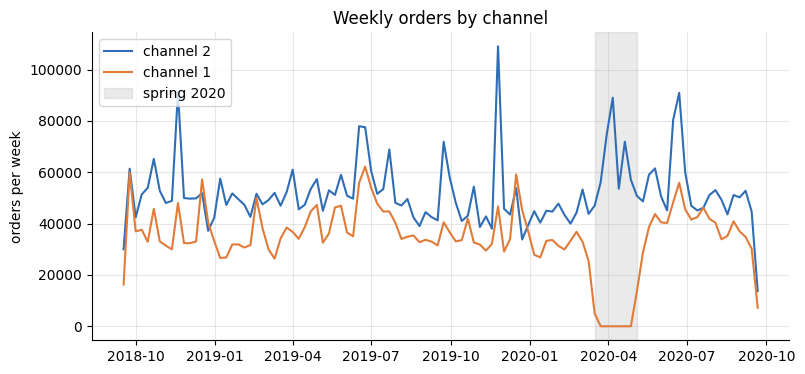

In [9]:
weekly = q("""
SELECT date_trunc('week', order_date) AS week, channel, count(*) AS orders
FROM orders
GROUP BY 1, 2
ORDER BY 1, 2
""")
w = weekly.pivot(index="week", columns="channel", values="orders").fillna(0)

fig, ax = plt.subplots()
ax.plot(w.index, w[2], color=BLUE, label="channel 2")
ax.plot(w.index, w[1], color=ORANGE, label="channel 1")
ax.axvspan(pd.Timestamp("2020-03-16"), pd.Timestamp("2020-05-04"), color=GREY, alpha=0.2, label="spring 2020")
ax.set_title("Weekly orders by channel")
ax.set_ylabel("orders per week")
ax.legend(loc="upper left")
fig.savefig(FIG / "channel_check.png", dpi=150, bbox_inches="tight")

w.loc["2020-03-02":"2020-05-18"].astype(int)

**Line by line**
- The SQL counts orders per week per channel. `date_trunc('week', ...)` rounds each date down to the Monday of its week.
- `pivot(...)` reshapes the result so each channel becomes its own column, which is easier to plot. `fillna(0)` puts a 0 in weeks where a channel had no orders.
- The two `ax.plot` lines draw one line per channel. `axvspan` shades the spring 2020 weeks.
- `savefig` keeps a copy of the chart for the README.
- The last line prints the weeks around the closure so I can read the exact numbers.

**What it shows:** channel 1 falls from about 33,000 orders a week in early March to about 5,000 in the week of 16 March. It then sits at **zero** from 23 March to the end of April (one stray order in the last week) and comes back in May. Channel 2 keeps going. Only stores closing explains that, so from here on **channel 1 = store and channel 2 = online**.

## 6. Where do "new" customers really start?

The data starts on 20 September 2018, but H&M obviously had customers before that. Someone who shopped every month for years still shows up as "new" in September 2018, because that's the first time this data sees them. If I counted those people as new, early cohorts would look far more loyal than they really are.

The test: in each month, what share of buyers are seen for the first time, and how often do those "new" customers come back within 90 days? Both numbers should start high and level off once the existing customers have washed out.

,month,buyers,new_customers,pct_new,return_90d_pct
0,2018-09-01,140340,140340,100.0,69.5
1,2018-10-01,274220,212669,77.6,62.8
2,2018-11-01,274207,138233,50.4,52.1
3,2018-12-01,254059,89944,35.4,45.8
4,2019-01-01,242024,68957,28.5,42.9
5,2019-02-01,238992,65453,27.4,39.4
6,2019-03-01,244166,51185,21.0,43.4
7,2019-04-01,260875,49884,19.1,43.3
8,2019-05-01,271554,48645,17.9,42.5
9,2019-06-01,305190,52127,17.1,38.4


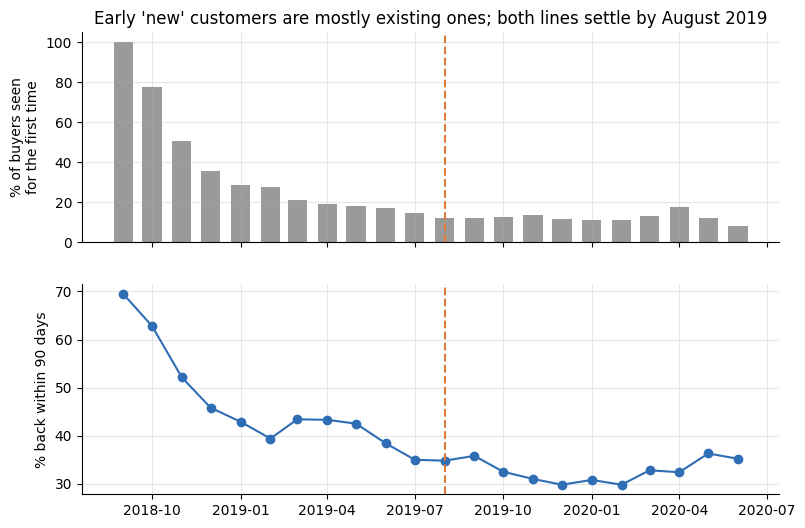

In [10]:
burn = q("""
WITH buyers AS (
    SELECT date_trunc('month', order_date) AS month, count(DISTINCT customer_id) AS buyers
    FROM orders GROUP BY 1
),
new AS (
    SELECT cohort_month AS month,
           count(*) AS new_customers,
           100.0 * avg(coalesce(days_to_second <= 90, false)::INT) AS return_90d_pct
    FROM firsts
    WHERE first_date <= DATE '2020-09-22' - INTERVAL 90 DAY
    GROUP BY 1
)
SELECT b.month, b.buyers, n.new_customers,
       round(100.0 * n.new_customers / b.buyers, 1) AS pct_new,
       round(n.return_90d_pct, 1) AS return_90d_pct
FROM buyers b JOIN new n USING (month)
ORDER BY b.month
""")

fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].bar(burn.month, burn.pct_new, width=20, color=GREY)
ax[0].set_ylabel("% of buyers seen\nfor the first time")
ax[1].plot(burn.month, burn.return_90d_pct, marker="o", color=BLUE)
ax[1].set_ylabel("% back within 90 days")
for a in ax:
    a.axvline(pd.Timestamp("2019-08-01"), color=ORANGE, linestyle="--")
ax[0].set_title("Early 'new' customers are mostly existing ones; both lines settle by August 2019")
fig.savefig(FIG / "burn_in.png", dpi=150, bbox_inches="tight")
burn

**Line by line**
- The `buyers` CTE counts everyone who bought in each month. A CTE (`WITH ... AS`) is a named subquery that keeps the main query readable.
- The `new` CTE counts customers whose first purchase fell in that month and the share who came back within 90 days.
- `coalesce(days_to_second <= 90, false)` handles customers who never returned. Their gap is empty, and without `coalesce` they'd be left out of the average, which would make the return rate look higher than it is. With it, they count as "did not return".
- `WHERE first_date <= DATE '2020-09-22' - INTERVAL 90 DAY` keeps only customers whose full 90 days are inside the data. Anyone who first bought in late summer 2020 hasn't had 90 days yet, and including them would drag the rate down.
- The main query joins the two and works out `pct_new`.
- The chart has two panels with a dashed line at August 2019.

**What it shows**
- In October 2018, 77.6% of buyers are "new" and they come back 62.8% of the time. That isn't a new-customer number; it's existing customers being counted for the first time.
- Both lines fall through the first year and settle from **August 2019**. From then on about 9% to 14% of each month's buyers are new, and 30% to 36% of them come back within 90 days.

**Decision:** I only treat first purchases from August 2019 onward as real first purchases. That throws away the first 11 months, but a customer who first shows up in August 2019 or later had at least 10.5 months with no purchase before it. They're either genuinely new or coming back after a long break.

This also changes one part of my plan. I wanted to compare spring 2020 with spring 2019, but spring 2019 falls inside the period I just dropped, so that comparison would be unfair. Section 13 compares spring 2020 with the months just before it instead.

## 7. How long to wait for a second order

"Did the customer come back?" needs a time limit. Too short and slow returners get counted as lost. Too long and only the oldest cohorts can be measured at all. I let the data choose: when do second orders actually arrive?

,day,pct_of_first_buyers,pct_of_year_returners
6,7,10.5,18.1
13,14,14.5,25.1
29,30,20.6,35.5
59,60,28.9,50.0
89,90,35.0,60.5
119,120,39.8,68.8
179,180,45.8,79.2
269,270,52.4,90.6
364,365,57.9,100.0


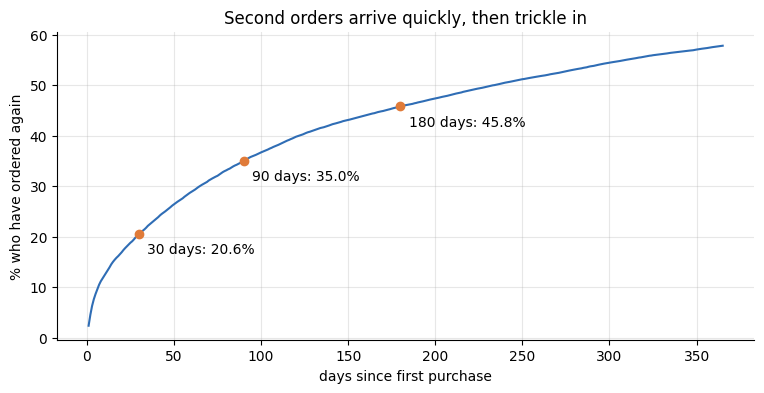

In [11]:
curve = q("""
WITH base AS (
    SELECT days_to_second FROM firsts
    WHERE first_date BETWEEN DATE '2019-08-01' AND DATE '2019-09-22'
)
SELECT d.day,
       100.0 * count(*) FILTER (WHERE days_to_second <= d.day) / count(*) AS pct_of_first_buyers
FROM base, range(1, 366) AS d(day)
GROUP BY d.day
ORDER BY d.day
""")
year_back = curve.pct_of_first_buyers.iloc[-1]
curve["pct_of_year_returners"] = 100 * curve.pct_of_first_buyers / year_back

fig, ax = plt.subplots()
ax.plot(curve.day, curve.pct_of_first_buyers, color=BLUE)
for d in (30, 90, 180):
    v = curve.loc[curve.day == d, "pct_of_first_buyers"].item()
    ax.scatter(d, v, color=ORANGE, zorder=3)
    ax.annotate(f"{d} days: {v:.1f}%", (d, v), xytext=(6, -14), textcoords="offset points")
ax.set_xlabel("days since first purchase")
ax.set_ylabel("% who have ordered again")
ax.set_title("Second orders arrive quickly, then trickle in")
fig.savefig(FIG / "return_window.png", dpi=150, bbox_inches="tight")

curve[curve.day.isin([7, 14, 30, 60, 90, 120, 180, 270, 365])].round(1)

**Line by line**
- `base` takes customers who first bought between 1 August and 22 September 2019. They're past the burn-in, and every one of them has a full year of data afterwards, so nobody's year is cut short.
- `range(1, 366) AS d(day)` makes a list of days 1 to 365. Writing `FROM base, range(...)` pairs every customer with every day.
- For each day, `count(*) FILTER (WHERE days_to_second <= d.day) / count(*)` is the share of customers who had ordered again by then. That gives a cumulative curve.
- In pandas, `pct_of_year_returners` rescales the curve so 100% means everyone who came back within the year.
- The loop marks 30, 90 and 180 days on the chart.

**What it shows**
- 57.9% of first-time buyers order again within a year.
- Among customers who return within a year, 35.5% are back within 30 days, 60.5% within 90 days and 79.2% within 180 days.

**Decision: a 90-day window.**
- It catches about 60% of customers who will return within the year.
- It's a quarter, which is easy to explain.
- It still lets me measure customers who first bought as late as June 2020, which keeps the store-closure months in the analysis. A 180-day window would stop at March 2020 and lose them.

Section 12 reruns the main model with 180 days to check that the choice doesn't change the answer.

## 8. Cohort retention

The classic view: for each month's new customers, what share buy again 1, 2, 3 and more months later?

k,1,2,3,4,5,6,7,8,9,10,11,12
cohort_month,,,,,,,,,,,,
Aug 2019,13.9,13.4,12.9,12.8,10.8,10.4,9.4,9.8,10.8,14.2,12.6,11.8
Sep 2019,16.0,14.1,13.6,11.1,10.8,10.2,10.8,11.2,13.9,12.0,12.0,NaN
Oct 2019,14.9,13.0,10.3,10.4,9.2,9.6,10.8,13.1,11.3,10.5,NaN,NaN
Nov 2019,14.2,10.4,10.0,9.0,9.2,10.0,12.7,10.9,9.8,NaN,NaN,NaN
Dec 2019,12.3,10.9,9.0,9.5,10.5,13.5,11.1,10.3,NaN,NaN,NaN,NaN
Jan 2020,12.7,10.5,10.8,10.8,13.3,11.6,10.8,NaN,NaN,NaN,NaN,NaN
Feb 2020,11.8,10.5,11.0,13.4,11.4,10.3,NaN,NaN,NaN,NaN,NaN,NaN
Mar 2020,14.7,12.5,14.1,10.9,10.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Apr 2020,13.9,13.8,10.2,9.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


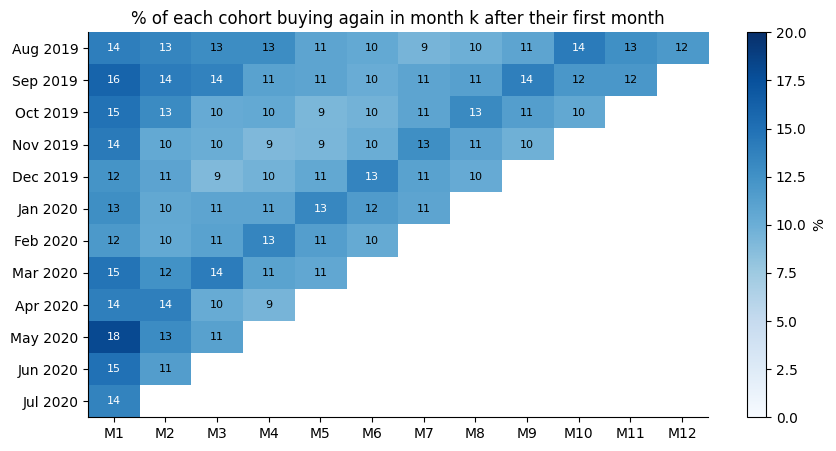

In [12]:
cohorts = q("""
WITH cust AS (
    SELECT customer_id, cohort_month FROM firsts
    WHERE cohort_month >= DATE '2019-08-01'
),
active AS (
    SELECT DISTINCT o.customer_id, c.cohort_month,
           date_diff('month', c.cohort_month, date_trunc('month', o.order_date)) AS k
    FROM orders o JOIN cust c USING (customer_id)
),
sizes AS (
    SELECT cohort_month, count(*) AS cohort_size FROM cust GROUP BY 1
)
SELECT a.cohort_month, s.cohort_size, a.k,
       count(*) AS active_customers,
       100.0 * count(*) / s.cohort_size AS retention_pct
FROM active a JOIN sizes s USING (cohort_month)
WHERE a.k BETWEEN 1 AND 12
  AND a.cohort_month + to_months(a.k + 1) <= DATE '2020-09-01'
GROUP BY 1, 2, 3
ORDER BY 1, 3
""")

grid = cohorts.pivot(index="cohort_month", columns="k", values="retention_pct")
grid.index = grid.index.strftime("%b %Y")

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(grid.values, cmap="Blues", aspect="auto", vmin=0, vmax=20)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 13 else "black")
ax.set_xticks(range(grid.shape[1]), [f"M{k}" for k in grid.columns])
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
ax.set_title("% of each cohort buying again in month k after their first month")
fig.colorbar(im, ax=ax, label="%")
fig.savefig(FIG / "cohort_heatmap.png", dpi=150, bbox_inches="tight")
grid.round(1)

**Line by line**
- `cust` keeps customers whose first purchase was in August 2019 or later, matching the section 6 decision.
- `active` finds every month in which each customer bought anything. `k` is how many months after their first month that was, so k = 1 means the next calendar month. `DISTINCT` counts a customer once per month, however many orders they placed.
- `sizes` counts the customers in each cohort.
- The main query divides active customers by cohort size to get the retention percentage.
- `cohort_month + to_months(k + 1) <= DATE '2020-09-01'` keeps only months that are fully inside the data. The data stops on 22 September, so September 2020 is incomplete and would look like a drop that never happened.
- In pandas, `pivot` turns the long table into a grid with cohorts as rows and months as columns, and `imshow` colors it. The loop writes each percentage in its cell, in white on dark cells so it stays readable.

**What it shows**
- About 12% to 18% of a cohort buys again in the very next month.
- After that, the curve barely falls: roughly 9% to 14% of every cohort is active in any later month, out to month 12.
- So the big loss happens right after the first purchase. A customer who makes it to a second month tends to stick around, which is why the rest of this notebook focuses on that first return.
- The darker cells in the 2019 cohorts' later months line up with the same calendar months, which points to seasonal sales pulling people back.

## 9. Building one row per first order

Now the core question. For every first purchase from 1 August 2019 to 24 June 2020 (the last date with a full 90 days of data after it), I describe what was in the basket and whether the customer came back within 90 days.

In [13]:
con.sql("""
CREATE OR REPLACE TABLE first_orders AS
WITH f AS (
    SELECT customer_id, first_date, cohort_month, days_to_second
    FROM firsts
    WHERE first_date BETWEEN DATE '2019-08-01' AND DATE '2020-06-24'
),
typical AS (
    SELECT article_id, median(price) AS typical_price
    FROM t GROUP BY article_id
),
items AS (
    SELECT f.*, x.article_id, x.price, x.sales_channel_id,
           a.product_group_name, a.index_group_name, p.typical_price
    FROM f
    JOIN t x       ON x.customer_id = f.customer_id AND x.t_dat = f.first_date
    JOIN a         ON a.article_id = x.article_id
    JOIN typical p ON p.article_id = x.article_id
),
dept AS (
    SELECT customer_id, index_group_name AS main_department,
           row_number() OVER (PARTITION BY customer_id
                              ORDER BY count(*) DESC, index_group_name) AS rank
    FROM items
    GROUP BY customer_id, index_group_name
)
SELECT i.customer_id, i.first_date, i.cohort_month,
       coalesce(any_value(i.days_to_second) <= 90, false)  AS returned_90d,
       coalesce(any_value(i.days_to_second) <= 180, false) AS returned_180d,
       count(*)                             AS items,
       count(DISTINCT i.product_group_name) AS product_groups,
       CASE WHEN count(DISTINCT i.sales_channel_id) = 2 THEN 'both'
            WHEN max(i.sales_channel_id) = 2 THEN 'online'
            ELSE 'store' END                AS channel,
       any_value(d.main_department)         AS main_department,
       avg((i.price < 0.9 * i.typical_price)::INT) AS markdown_share,
       sum(i.price)                         AS order_value
FROM items i
JOIN dept d ON d.customer_id = i.customer_id AND d.rank = 1
GROUP BY i.customer_id, i.first_date, i.cohort_month
""")

df = q("""
SELECT f.*, c.age, coalesce(c.club_member_status, 'unknown') AS club,
       CASE WHEN f.first_date < DATE '2020-03-16' THEN 'before closure'
            WHEN f.first_date < DATE '2020-05-04' THEN 'stores closed'
            ELSE 'stores reopening' END AS period
FROM first_orders f JOIN c USING (customer_id)
""")
print(f"{len(df):,} first orders, {df.returned_90d.mean():.1%} came back within 90 days")
df.head(3)

330,336 first orders, 32.8% came back within 90 days


,customer_id,first_date,cohort_month,returned_90d,returned_180d,items,product_groups,channel,main_department,markdown_share,order_value,age,club,period
0,ff30e82c5c2f78af24c33fb301cf46cdc0589788b7f95b...,2019-10-09,2019-10-01,False,False,5,2,online,Sport,0.0,0.169407,52,ACTIVE,before closure
1,ff30ffbc9dc7f4c30b5cef75a12fc3b711b5d5a5c151d9...,2019-08-24,2019-08-01,True,True,5,3,store,Divided,0.8,0.121949,43,ACTIVE,before closure
2,ff3117b0dddfb6e619bbf483e2eb1ece3706f3c96a0562...,2020-06-06,2020-06-01,True,True,1,1,online,Ladieswear,0.0,0.025407,51,ACTIVE,stores reopening


**Line by line**
- `f` picks the first purchases to study. The start date comes from section 6. The end date, 24 June 2020, is 90 days before the data ends.
- `typical` works out each article's usual price: the median price it sold at across all two years. I use it to tell whether a first purchase was bought on markdown.
- `items` pulls back every item from each customer's first day by joining the transactions on customer and date, then adds the product details and typical price.
- The final `SELECT` rolls the items up to one row per customer:
  - `returned_90d` and `returned_180d` are the outcomes, with `coalesce` again so customers who never returned count as `false`.
  - `items` is how many items were in the first basket.
  - `product_groups` counts how many kinds of product were bought, such as tops plus shoes.
  - `channel` is `store`, `online`, or `both` if they used both on that first day.
  - `main_department` comes from the `dept` step, which counts items per department in each basket and ranks them. `ORDER BY count(*) DESC, index_group_name` puts the biggest department first and breaks ties alphabetically, so a basket split evenly between two departments gets the same answer every time the notebook runs.
  - `markdown_share` is the share of items bought more than 10% below their typical price. `(price < 0.9 * typical_price)::INT` turns true and false into 1 and 0, so the average is a share.
- The second query adds age and club status from the customers table, and labels each first purchase as before the store closures, during them, or after stores reopened. The dates come from the channel check in section 5.

**What it shows:** 330,336 first orders, and 32.8% came back within 90 days. That's the baseline every driver below is compared against.

In [14]:
age = df.age.astype("float")
df["age_band"] = np.select([age.isna(), age < 25, age < 35, age < 45, age < 55],
                           ["unknown", "16-24", "25-34", "35-44", "45-54"], "55+")
df["items_band"] = pd.cut(df["items"], [0, 1, 2, 3, 5, 9, np.inf],
                          labels=["1", "2", "3", "4-5", "6-9", "10+"])
df["groups_band"] = np.minimum(df.product_groups, 4).astype(str).replace("4", "4+")
df["club_group"] = np.where(df.club.isin(["ACTIVE", "PRE-CREATE"]), df.club, "other")
df["markdown"] = np.select([df.markdown_share == 0, df.markdown_share == 1],
                           ["none on markdown", "all on markdown"], "some on markdown")
df["channel_group"] = np.where(df.channel == "store", "store", "online")
df["month"] = df.cohort_month.dt.strftime("%m")
df["y"] = df.returned_90d.astype(int)
df[["items", "items_band", "groups_band", "channel_group", "club_group", "markdown", "age_band"]].head()

,items,items_band,groups_band,channel_group,club_group,markdown,age_band
0,5,4-5,2,online,ACTIVE,none on markdown,45-54
1,5,4-5,3,store,ACTIVE,some on markdown,35-44
2,1,1,1,online,ACTIVE,none on markdown,45-54
3,1,1,1,online,ACTIVE,none on markdown,45-54
4,2,2,1,online,ACTIVE,none on markdown,16-24


**Line by line:** this cell turns raw numbers into bands that are easier to compare.
- `age.astype("float")` turns missing ages into proper NaN values so the comparisons in `np.select` work.
- `np.select([...], [...], "55+")` checks the conditions in order and uses `55+` when none match.
- `pd.cut` splits basket size into bands. `[0, 1, 2, 3, 5, 9, inf]` means 1, 2, 3, 4 to 5, 6 to 9, and 10 or more. It also keeps the 570-item basket from section 3 from stretching any scale.
- `np.minimum(..., 4)` caps product groups at 4 and relabels that band "4+".
- `club_group` keeps ACTIVE and PRE-CREATE and puts the rare values (LEFT CLUB and missing, about 1,000 people) into "other".
- `channel_group` folds the 892 customers who used both channels on day one into "online". There are too few of them for their own group.
- `month` is the calendar month of the first purchase. It goes into the model so seasonal effects don't get credited to anything else.
- `y` is the outcome as 1 or 0, which the regression needs.

## 10. Each driver on its own

For each driver, the share of customers who came back within 90 days, with group sizes so tiny groups don't mislead.

,driver,group,customers,return_90d_pct
0,Items in first basket,1,96308,29.4
1,Items in first basket,2,80284,32.1
2,Items in first basket,3,46528,34.0
3,Items in first basket,4-5,53135,35.1
4,Items in first basket,6-9,36846,36.0
5,Items in first basket,10+,17235,38.5
6,Product groups in first basket,1,194178,30.5
7,Product groups in first basket,2,88801,35.4
8,Product groups in first basket,3,33129,37.0
9,Product groups in first basket,4+,14228,38.6


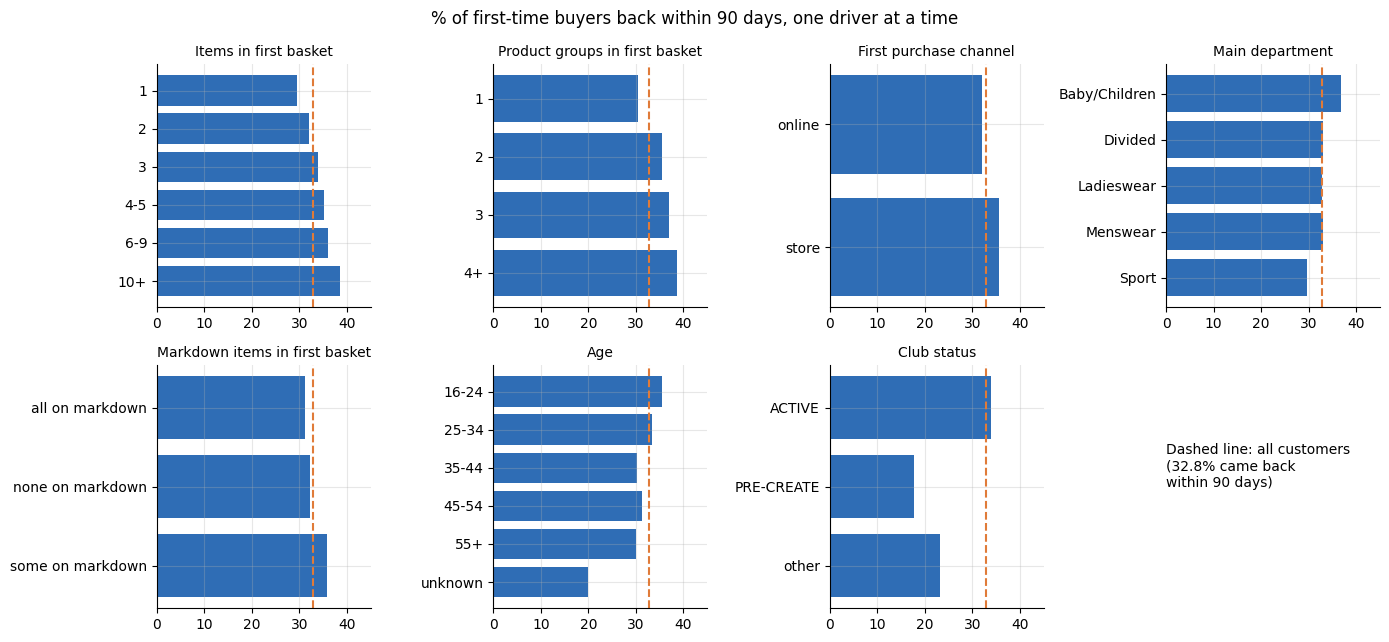

In [15]:
drivers = {
    "items_band": "Items in first basket",
    "groups_band": "Product groups in first basket",
    "channel_group": "First purchase channel",
    "main_department": "Main department",
    "markdown": "Markdown items in first basket",
    "age_band": "Age",
    "club_group": "Club status",
}
rows = []
for col, label in drivers.items():
    g = df.groupby(col, observed=True).y.agg(customers="size", rate="mean").reset_index()
    g.insert(0, "driver", label)
    rows.append(g.rename(columns={col: "group"}))
by_driver = pd.concat(rows, ignore_index=True)
by_driver["return_90d_pct"] = (100 * by_driver.rate).round(1)
by_driver = by_driver.drop(columns="rate")

base = 100 * df.y.mean()
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, (label, g) in zip(axes.flat, by_driver.groupby("driver", sort=False)):
    ax.barh(g.group.astype(str), g.return_90d_pct, color=BLUE)
    ax.axvline(base, color=ORANGE, linestyle="--")
    ax.set_title(label, fontsize=10)
    ax.set_xlim(0, 45)
    ax.invert_yaxis()
axes.flat[-1].axis("off")
axes.flat[-1].text(0, 0.5, f"Dashed line: all customers\n({base:.1f}% came back\nwithin 90 days)", fontsize=10)
fig.suptitle("% of first-time buyers back within 90 days, one driver at a time")
fig.tight_layout()
fig.savefig(FIG / "drivers.png", dpi=150, bbox_inches="tight")
by_driver

**Line by line**
- `drivers` maps each column to a readable label for the charts.
- The loop groups customers by one driver at a time. `.y.agg(customers="size", rate="mean")` counts each group and averages the 1s and 0s, which gives the return rate. `observed=True` skips empty bands.
- `pd.concat` stacks all the small tables into one long table, which is also exported in section 15.
- The chart draws one small bar chart per driver, with the overall 32.8% as a dashed line so each group reads as above or below average.

**What it shows**
- **Club status stands out most.** PRE-CREATE customers, whose membership was started but never completed, come back 17.8% of the time against 34.0% for active members. That's roughly half the rate.
- **Bigger, broader first baskets come back more.** One item: 29.4%. Ten or more: 38.5%. Customers whose basket covers four or more product groups: 38.6%, against 30.5% for a single group.
- **Store first-timers come back more than online ones:** 35.7% against 32.0%.
- **Younger customers come back a little more.** Sport is the weakest department.
- Markdown looks mixed here, but these drivers overlap: a basket can only be "some on markdown" if it has at least two items. Section 11 separates them.

## 11. All drivers together

The drivers overlap. Bigger baskets cover more product groups, and online shoppers skew younger. A logistic regression estimates each driver's link to returning **while holding the others constant**. I report odds ratios: 1.20 means 20% higher odds of coming back than the reference group, and 0.80 means 20% lower.

This model is here to **explain**, not to predict, so a simple model I can read beats a black box.

In [16]:
df["log_items"] = np.log(np.minimum(df["items"], 10))
formula = ("y ~ log_items + C(groups_band, Treatment('1'))"
           " + C(channel_group, Treatment('online'))"
           " + C(main_department, Treatment('Ladieswear'))"
           " + C(markdown, Treatment('none on markdown'))"
           " + C(age_band, Treatment('25-34'))"
           " + C(club_group, Treatment('ACTIVE'))"
           " + C(month)")
model = smf.logit(formula, data=df).fit(disp=0)

ors = pd.DataFrame({"odds_ratio": np.exp(model.params),
                    "ci_low": np.exp(model.conf_int()[0]),
                    "ci_high": np.exp(model.conf_int()[1]),
                    "p_value": model.pvalues})
ors = ors.drop(index=[i for i in ors.index if i == "Intercept" or i.startswith("C(month)")])

NAMES = {"groups_band": "product groups", "channel_group": "first channel", "main_department": "department",
         "markdown": "markdown", "age_band": "age", "club_group": "club status"}
def tidy(index):
    """Turn statsmodels names like C(age_band, Treatment('25-34'))[T.16-24] into 'age: 16-24'."""
    index = index.str.replace(r"C\((\w+), Treatment\('[^']*'\)\)\[T\.(.+)\]",
                              lambda m: f"{NAMES[m.group(1)]}: {m.group(2)}", regex=True)
    return index.str.replace("log_items", "items (log scale)")

ors.index = tidy(ors.index)
print(f"n = {int(model.nobs):,}   pseudo R-squared = {model.prsquared:.3f}")
ors.round(3)

n = 330,336   pseudo R-squared = 0.014


,odds_ratio,ci_low,ci_high,p_value
product groups: 2,1.149,1.127,1.172,0.000
product groups: 3,1.167,1.133,1.202,0.000
product groups: 4+,1.200,1.152,1.251,0.000
first channel: store,1.141,1.120,1.163,0.000
department: Baby/Children,1.199,1.135,1.266,0.000
department: Divided,0.989,0.972,1.006,0.196
department: Menswear,1.014,0.977,1.053,0.454
department: Sport,0.863,0.828,0.900,0.000
markdown: all on markdown,0.890,0.873,0.908,0.000
markdown: some on markdown,0.965,0.945,0.985,0.001


**Line by line**
- `log_items` takes the log of basket size, capped at 10. Going from 1 item to 2 probably matters more than going from 9 to 10, and the log captures that.
- The `formula` is written the way statisticians write models: the outcome `y` on the left, the drivers on the right.
  - `C(...)` marks a driver as a category.
  - `Treatment('...')` picks the reference group everything is compared against, such as online for channel, Ladieswear for department and ACTIVE for club status.
  - `C(month)` adjusts for the calendar month of the first purchase, so a seasonal effect isn't credited to another driver.
- `smf.logit(...).fit()` fits the model. `disp=0` hides the fitting log.
- `np.exp(model.params)` turns the model's coefficients into odds ratios, and `conf_int()` gives the 95% confidence interval for each.
- I drop the intercept and month rows from the table, since they're controls rather than findings.
- `tidy()` rewrites statsmodels' long names into short labels with a regular expression. `C(age_band, Treatment('25-34'))[T.16-24]` becomes `age: 16-24`. The `NAMES` dictionary supplies the readable driver names.

**What it shows**
- **Club status is still the biggest signal.** PRE-CREATE customers have **0.45 times** the odds of coming back (95% CI 0.44 to 0.47). Holding everything else equal, that's less than half.
- **Breadth matters beyond size.** With basket size held constant, two product groups raise the odds by 15%, and four or more by 20%. More items also help on their own.
- **Store first-timers** have 14% higher odds than online first-timers.
- **Customers whose whole first basket was on markdown** have 11% lower odds than those who paid full price. Once basket size is held constant, deal-only first purchases look weaker. The "some on markdown" bump in section 10 was really a basket-size effect.
- **Age and department:** 16 to 24 year olds have 11% higher odds than 25 to 34 year olds, and Sport first purchases have 14% lower odds than Ladieswear.
- Every interval is narrow because the sample is large, so these differences are not noise.

**The honest limit:** the pseudo R-squared is **0.014**. The first order shifts the odds in clear, consistent ways, but most of what decides whether someone comes back isn't visible in their first purchase. These are levers, not a crystal ball.

**One caveat on club status:** it's a snapshot from when the data was published, not from the day of the first purchase. Some customers may have finished signing up *because* they kept shopping, which would make the link partly run the other way. The safe reading is that customers who never complete membership rarely come back, and that's still worth watching.

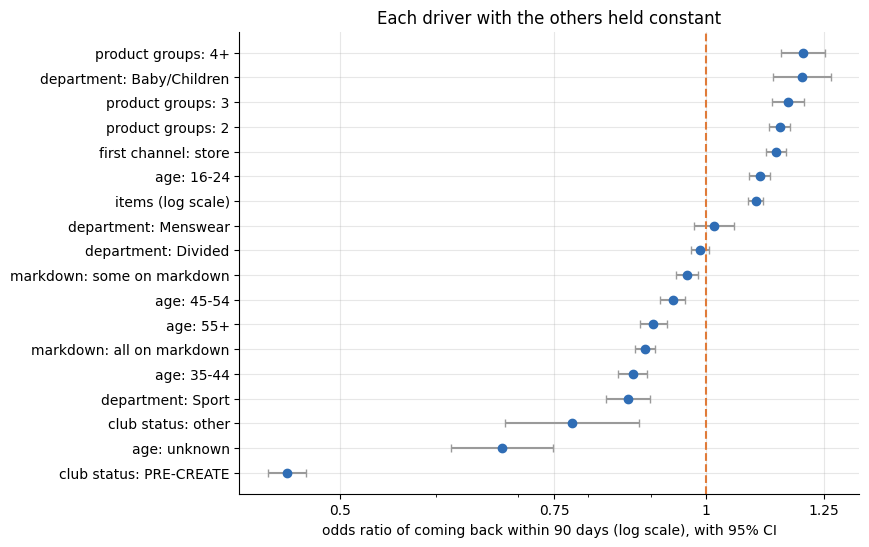

In [17]:
plot = ors.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(plot.odds_ratio, range(len(plot)),
            xerr=[plot.odds_ratio - plot.ci_low, plot.ci_high - plot.odds_ratio],
            fmt="o", color=BLUE, ecolor=GREY, capsize=3)
ax.axvline(1, color=ORANGE, linestyle="--")
ax.set_yticks(range(len(plot)), plot.index)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.75, 1, 1.25], ["0.5", "0.75", "1", "1.25"])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("odds ratio of coming back within 90 days (log scale), with 95% CI")
ax.set_title("Each driver with the others held constant")
fig.savefig(FIG / "odds_ratios.png", dpi=150, bbox_inches="tight")

**Line by line**
- `sort_values` orders the drivers from the strongest negative to the strongest positive.
- `errorbar` draws each odds ratio as a dot with its confidence interval as a line. `xerr` needs the distance from the dot to each end of the interval, which is why it subtracts.
- The dashed line at 1 means "no difference from the reference group". Anything to its left lowers the odds and anything to its right raises them.
- A log scale makes 0.5 (half the odds) and 2 (double the odds) sit the same distance from 1, so effects in both directions read fairly. `NullFormatter` hides the automatic in-between tick labels, which matplotlib writes in scientific notation.

### The same effects in percentage points

Odds ratios are hard to act on. "0.45 times the odds" doesn't tell a product manager how many customers that is. Average marginal effects answer the plainer question: holding everything else the same, how many **percentage points** more or less likely is a customer to come back?

In [18]:
me = model.get_margeff(at="overall", dummy=True).summary_frame()
me = me[~me.index.str.startswith("C(month)")]
margeff = pd.DataFrame({"pp_change": me["dy/dx"] * 100,
                        "pp_low": me["Conf. Int. Low"] * 100,
                        "pp_high": me["Cont. Int. Hi."] * 100})
# log_items is continuous: its effect is per one unit of log(items), so scale it to one doubling of the basket
margeff.loc["log_items"] *= np.log(2)
margeff.index = tidy(margeff.index).str.replace("items (log scale)", "items (per doubling)")
margeff = margeff.round(1).sort_values("pp_change")
margeff

,pp_change,pp_low,pp_high
club status: PRE-CREATE,-14.9,-15.5,-14.4
age: unknown,-7.8,-9.6,-6.0
club status: other,-5.2,-7.8,-2.7
department: Sport,-3.1,-4.0,-2.3
age: 35-44,-3.0,-3.5,-2.4
markdown: all on markdown,-2.5,-2.9,-2.1
age: 55+,-2.1,-2.7,-1.6
age: 45-54,-1.4,-1.9,-0.9
markdown: some on markdown,-0.8,-1.2,-0.3
department: Divided,-0.2,-0.6,0.1


**Line by line**
- `get_margeff(at="overall", dummy=True)` asks the fitted model a what-if question for every customer and averages the answers. `dummy=True` treats each category as a switch from the reference group to that group (for example online to store), which is the right reading for yes/no drivers.
- I drop the month rows, since they're controls, and multiply by 100 to get percentage points.
- Basket size enters the model as a log, so its raw effect is per unit of log(items). Multiplying by `np.log(2)` turns it into the effect of doubling the basket, say from 2 items to 4.
- `tidy()` from section 11 gives the rows readable names.

**What it shows**, against the 32.8% baseline:
- **Unfinished sign-up (PRE-CREATE):** 14.9 pp less likely to come back (95% CI 15.5 to 14.4 pp lower). Still the largest gap, with the same snapshot caveat as before.
- **A first basket covering 4 or more product groups:** 4.1 pp more likely (CI 3.1 to 5.0 pp), on top of whatever basket size adds.
- **First purchase in a store:** 2.9 pp more likely than online.
- **A first basket bought entirely on markdown:** 2.5 pp less likely than one bought at full price.
- **Age 16 to 24:** 2.2 pp more likely than 25 to 34. **Sport** as the main department: 3.1 pp less likely than Ladieswear.
- **Doubling the basket:** 1.4 pp more likely.

So the levers a product team can touch (breadth of the first basket, how much of it is discounted) move the return rate by roughly 2 to 4 points each. That's real at 30,000 new customers a month, but it's not transformational, and it says nothing yet about cause.

### How big is that in customers?

A rough sizing for the breadth lever. Suppose a "complete the look" suggestion turned 10% of single-category first baskets into two-category baskets, and suppose the observational effect held in full. How many extra customers would come back each month?

In [19]:
monthly_first_buyers = len(df) / df.cohort_month.nunique()
single_share = (df.product_groups == 1).mean()
lift_two_groups = me.loc["C(groups_band, Treatment('1'))[T.2]", "dy/dx"]
converted = 0.10

extra_returners = monthly_first_buyers * single_share * converted * lift_two_groups
print(f"first-time buyers per month: {monthly_first_buyers:,.0f}")
print(f"single-category first baskets: {single_share:.1%}")
print(f"lift from a second category: {lift_two_groups * 100:.2f} pp")
print(f"extra returning customers per month: {extra_returners:,.0f}")
scenarios = pd.DataFrame({"share_converted": [0.05, 0.10, 0.25]})
scenarios["extra_returners_per_month"] = (monthly_first_buyers * single_share * scenarios.share_converted
                                          * lift_two_groups).round()
scenarios

first-time buyers per month: 30,031
single-category first baskets: 58.8%
lift from a second category: 3.05 pp
extra returning customers per month: 54


,share_converted,extra_returners_per_month
0,0.05,27.0
1,0.10,54.0
2,0.25,135.0


**Line by line**
- `monthly_first_buyers` divides the 330,336 first-time buyers by the 11 cohort months.
- `single_share` is the share whose first basket held only one product group, which is the group a suggestion could move.
- `lift_two_groups` takes the marginal effect of a two-group basket from the table above, kept unrounded.
- The product of the four numbers is the extra returners per month. The small table repeats it for 5%, 10% and 25% of baskets converted.

**What it shows:** about 30,000 first-time buyers a month, 58.8% of them with a single-category first basket. At 10% converted, that's about 54 extra returning customers a month, and about 135 at 25%.

That's an **upper bound**. It assumes the whole observational gap is causal, and some of it is surely customers who were already keener buying more broadly. The honest takeaway for a product team is that this lever is worth a cheap test, not a big bet. The next section designs that test.

## 12. Does the answer change with a 180-day window?

I picked 90 days in section 7. To check that the choice doesn't drive the results, I refit the same model on customers who first bought by 26 March 2020, since they have a full 180 days of data. I fit it twice on that same group, once with each window.

In [20]:
sub = df[df.first_date <= "2020-03-26"].copy()
fits = {}
for window in ("90d", "180d"):
    sub["y"] = sub[f"returned_{window}"].astype(int)
    m = smf.logit(formula, data=sub).fit(disp=0)
    fits[window] = np.exp(m.params)
compare = pd.DataFrame(fits)
compare = compare.loc[[i for i in compare.index if i != "Intercept" and not i.startswith("C(month)")]]
compare.index = tidy(compare.index)
compare["same_direction"] = np.sign(np.log(compare["90d"])) == np.sign(np.log(compare["180d"]))
print(f"{len(sub):,} customers. Back within 90 days: {sub.returned_90d.mean():.1%}, within 180 days: {sub.returned_180d.mean():.1%}")
compare.round(3)

229,106 customers. Back within 90 days: 32.1%, within 180 days: 42.7%


,90d,180d,same_direction
product groups: 2,1.155,1.169,True
product groups: 3,1.174,1.170,True
product groups: 4+,1.194,1.207,True
first channel: store,1.062,1.064,True
department: Baby/Children,1.226,1.538,True
department: Divided,0.999,1.006,False
department: Menswear,1.073,1.114,True
department: Sport,0.850,0.858,True
markdown: all on markdown,0.850,0.822,True
markdown: some on markdown,0.897,0.858,True


**Line by line**
- `sub` keeps customers whose first purchase was on or before 26 March 2020, which is 180 days before the data ends.
- The loop fits the same formula twice on that same group, once with each outcome, and keeps the odds ratios.
- `same_direction` checks whether each driver points the same way under both windows. `np.log` of an odds ratio is negative below 1 and positive above 1, so comparing signs compares directions.

**What it shows**
- On the 229,106 customers with a full 180 days of data, 32.1% came back within 90 days and 42.7% within 180 days.
- **Every driver with a real effect points the same way under both windows.** Club status, product breadth, markdown, age, Sport and Baby/Children keep their direction, and most odds ratios barely move. The one flip is Divided (0.999 against 1.006), which is no effect under either window. So the 90-day choice isn't driving the results.
- **One thing does change, and it's not the window.** On this earlier group, store first-timers have only about 6% higher odds than online first-timers, against 14% in the full model. This group stops in March 2020, so it leaves out the customers who first bought in stores after reopening. Section 13 shows that group came back unusually often. A good part of the store advantage in section 11 comes from summer 2020, so I describe it as a modest effect, not a strong one.

## 13. Customers who arrived while stores were closed

From mid-March to early May 2020, the only way to make a first purchase was online. Section 6 showed April 2020 was the biggest month for new customers after the burn-in. Did these pandemic arrivals come back as often as the online customers who came before them?

,period,channel_group,customers,return_90d_pct
0,before closure,online,156855,31.2
1,before closure,store,62856,33.8
2,stores closed,online,57850,33.1
3,stores closed,store,212,29.2
4,stores reopening,online,42042,33.3
5,stores reopening,store,10521,46.9


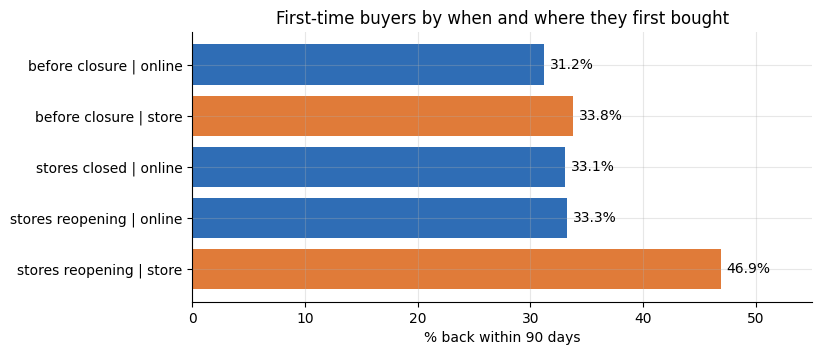

In [21]:
closure = (df.groupby(["period", "channel_group"])
             .y.agg(customers="size", return_90d="mean")
             .reset_index())
closure["return_90d_pct"] = (100 * closure.return_90d).round(1)
closure = closure.drop(columns="return_90d")

show = closure[closure.customers >= 1000]
fig, ax = plt.subplots(figsize=(8, 3.5))
labels = show.period + " | " + show.channel_group
ax.barh(labels, show.return_90d_pct, color=[BLUE if c == "online" else ORANGE for c in show.channel_group])
for y, v in enumerate(show.return_90d_pct):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center")
ax.invert_yaxis()
ax.set_xlim(0, 55)
ax.set_xlabel("% back within 90 days")
ax.set_title("First-time buyers by when and where they first bought")
fig.savefig(FIG / "store_closure.png", dpi=150, bbox_inches="tight")
closure

**Line by line**
- `groupby(["period", "channel_group"])` splits first-time buyers by when they arrived (before, during and after the closures) and where (store or online), and works out each group's 90-day return rate.
- `show` drops groups with fewer than 1,000 people for the chart. The table keeps them, but a rate from 212 customers isn't worth a bar.
- The bars are blue for online and orange for store, with the percentage written next to each.

**What it shows**
- **Online first-timers who arrived during the closures came back 33.1% of the time**, slightly above the 31.2% for online first-timers before the closures. There was no "pandemic tourist" effect: being forced online didn't bring in weaker customers.
- **Store first-timers after reopening came back 46.9% of the time**, well above any other group. The window for these customers (May to September 2020) includes the summer sales, and some may be returning customers who were away for over 10 months, so I treat this as a lead to dig into, not a finding.
- The 212 "store during closure" customers are the last few days before stores shut. There are too few of them to read anything from.

## 14. Testing the biggest lever: an experiment design

Everything so far is correlation. Customers who buy across categories come back more, but that doesn't prove that *getting* someone to buy across categories brings them back. The only way to find out is to test it.

**Hypothesis:** showing first-time buyers a complementary second category ("complete the look") at their first checkout raises the share who come back within 90 days. For Glance, the same test would suggest a second category right after a user's first try-on.

In [22]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

baseline = df.y.mean()
mde = 0.01                                    # smallest lift worth detecting: 1 percentage point
power = NormalIndPower()
n_per_arm = int(np.ceil(power.solve_power(proportion_effectsize(baseline + mde, baseline),
                                          alpha=0.05, power=0.8, ratio=1)))
print(f"baseline {baseline:.4f}, target {baseline + mde:.4f}, n per arm {n_per_arm:,}")
weeks_to_enroll = 2 * n_per_arm / monthly_first_buyers * 52 / 12
print(f"enrolment at {monthly_first_buyers:,.0f} new buyers a month: {weeks_to_enroll:.1f} weeks, then 90 days to read the result")

mde_table = pd.DataFrame({"lift_pp": [0.5, 1.0, 2.0]})
mde_table["n_per_arm"] = [int(np.ceil(power.solve_power(proportion_effectsize(baseline + l / 100, baseline),
                                                        alpha=0.05, power=0.8, ratio=1))) for l in mde_table.lift_pp]
experiment = pd.DataFrame([{"baseline": round(baseline, 4), "mde_pp": mde * 100, "alpha": 0.05,
                            "power": 0.8, "n_per_arm": n_per_arm, "weeks_to_enroll": round(weeks_to_enroll, 1)}])
mde_table

baseline 0.3281, target 0.3381, n per arm 34,868
enrolment at 30,031 new buyers a month: 10.1 weeks, then 90 days to read the result


,lift_pp,n_per_arm
0,0.5,138949
1,1.0,34868
2,2.0,8781


**Line by line**
- `baseline` is today's 90-day return rate, 32.8%.
- `mde = 0.01` is the minimum detectable effect: the smallest lift worth finding, 1 percentage point.
- `proportion_effectsize` turns "32.8% versus 33.8%" into a standard effect size. `solve_power` then finds how many customers each group needs to catch that difference 80% of the time (`power=0.8`) with a 5% false-alarm rate (`alpha=0.05`). `np.ceil` rounds up, because you can't enrol part of a person.
- `weeks_to_enroll` converts the two groups' total into weeks of new customers.
- `mde_table` shows how the size changes if the bar is set at 0.5, 1 or 2 points.

**What it shows:** **34,868 customers per arm**, about 69,700 in total. At about 30,000 new buyers a month, that's roughly 10 weeks of enrolment, then 90 days before the main result can be read. Halving the bar to 0.5 points would need about four times as many customers, which is why I set it at 1 point.

**Why 1 point?** In the observational data, customers who actually bought two categories came back about 3 points more often. A suggestion will only change some baskets, so the lift across *everyone shown it* will be smaller. One point is a realistic and still worthwhile target.

**The design**
- **Randomization:** randomize customers 50/50 when they reach their first checkout, by a hash of their customer ID, so the same person always sees the same version. Randomizing at checkout means everyone in the test is a first-time buyer, so today's 32.8% baseline applies. Randomizing earlier would bias the comparison, because the suggestion could change who buys at all, and comparing only the buyers would then mix two different groups of people. Check the split is close to 50/50 (a sample ratio mismatch check) before trusting any result.
- **Analysis:** intent to treat. Everyone who reached checkout stays in their group, including anyone who abandons the order after seeing the suggestion.
- **Primary metric:** 90-day return rate, the outcome this whole notebook is about.
- **Leading indicator:** product groups in the first basket. It's readable the same day. If it doesn't move in the first two weeks, the suggestion isn't changing behavior, so there's no point waiting 90 days.
- **Guardrails:** first-order value, so the suggestion doesn't shrink baskets; markdown share, because section 11 showed deal-only first baskets come back less, so suggesting discounted items could backfire; and checkout completion, so the suggestion doesn't make people abandon their first order.
- **Decision rule:** ship if the 90-day lift is positive and its 95% confidence interval excludes zero, and no guardrail is significantly worse. If the leading indicator moves but the 90-day rate doesn't, the observational link wasn't causal, and the lever should be dropped.
- **Pitfalls to avoid:** stopping early when the numbers look good (fix the sample size first), and a novelty effect from a brand-new widget, which is one more reason to judge on the 90-day outcome rather than the first week.

## 15. What I'd tell a product team

**Findings**
1. **The loss happens at the first return.** Only 32.8% of first-time buyers come back within 90 days. After month two, cohort retention barely moves, so the first few weeks are where effort pays off.
2. **Unfinished sign-up is the clearest warning sign.** Customers whose membership was never completed are 14.9 points less likely to come back. It's a snapshot measure, so part of the link may run the other way, but it's the most visible risk flag.
3. **Breadth beats size.** A first basket spanning 4 or more product groups is 4.1 points more likely to bring the customer back, even with basket size held constant.
4. **Deal-only first purchases are weaker.** An all-markdown first basket is 2.5 points less likely to lead to a return.
5. **Store first-timers come back a little more than online ones** (2.9 points overall, and a smaller gap once the post-reopening summer is left out, see section 12). Customers who arrived online during the closures came back just as well as earlier online customers.

**What I'd do next**
- **Run the experiment in section 14** before building anything bigger. It needs 34,868 customers per arm, about 10 weeks of new customers, and the leading indicator tells you within two weeks whether it's worth waiting for the 90-day result.
- **Treat onboarding completion as an activation metric** and put it on the dashboard. For an AI try-on product like Glance's, that's finishing the selfie step.
- **Don't lead with discounts to win first purchases.** Test style-led first experiences against discount-led ones, and judge them on return rate, not first conversion.

**Caveats**
- **This is observational data.** Every driver is an association, which is exactly why section 14 proposes a test.
- **The market is unknown.** H&M never named the market (postal codes are hashed), so patterns may differ elsewhere, including in India.
- **"First purchase" means first in this data,** after an 11-month burn-in.
- **Prices are scaled,** so spend is relative.
- **The first order explains little of the overall variation** (pseudo R-squared 0.014). The impact sizing in section 11 is an upper bound.

## 16. Exports for the Databricks dashboard

The Databricks dashboard rebuilds most of these tables in SQL, but the regression only runs here, so its results (`odds_ratios.csv`) are uploaded to Databricks for the dashboard's driver chart. The other files are small copies of each result, handy for checking the SQL version or loading into any other BI tool.

In [23]:
exports = {
    "weekly_channel.csv": weekly.assign(channel=weekly.channel.map({1: "store", 2: "online"})),
    "burn_in.csv": burn,
    "return_window.csv": curve,
    "cohort_retention.csv": cohorts.assign(cohort=cohorts.cohort_month.dt.strftime("%Y-%m")),
    "return_by_driver.csv": by_driver,
    "odds_ratios.csv": ors.reset_index(names="driver_group"),
    "store_closure.csv": closure,
    "marginal_effects.csv": margeff.reset_index(names="driver_group"),
    "experiment.csv": experiment,
}
for name, frame in exports.items():
    frame.to_csv(OUT / name, index=False)
    print(f"{name:<22} {len(frame):>4} rows")

weekly_channel.csv      207 rows
burn_in.csv              22 rows
return_window.csv       365 rows
cohort_retention.csv     78 rows
return_by_driver.csv     29 rows
odds_ratios.csv          18 rows
store_closure.csv         6 rows
marginal_effects.csv     18 rows
experiment.csv            1 rows


**Line by line**
- `exports` maps each file name to the table behind one dashboard view. `.map({1: "store", 2: "online"})` swaps the channel codes for the labels proven in section 5.
- `marginal_effects.csv` and `experiment.csv` carry the percentage-point effects and the experiment sizing, so the README and the dashboard quote the same numbers as this notebook.
- `.assign(cohort=...)` adds a text version of the cohort month, which sorts cleanly in BI tools.
- The loop writes each table to `exports/` and prints its row count, so I can check nothing came out empty.